In [1]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-10-05 06:18:20--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt.2’

input.txt.2         100%[===================>]   1.06M  --.-KB/s    in 0.03s   

2026-10-05 06:18:20 (38.6 MB/s) - ‘input.txt.2’ saved [1115394/1115394]



In [2]:
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

In [3]:
print("length of dataset in characters: ", len(text))

length of dataset in characters:  1115394


In [4]:
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



In [5]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(''.join(chars))
print(vocab_size)


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
65


In [6]:
stoi = { ch:i for i, ch in enumerate(chars) }
itos = { i:ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

print(encode("hi there"))
print(decode(encode("hi there")))

[46, 47, 1, 58, 46, 43, 56, 43]
hi there


In [7]:
import torch
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:1000])

torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59,  1, 39, 56, 43,  1, 39, 50, 50,
         1, 56, 43, 57, 53, 50, 60, 43, 42,  1, 56, 39, 58, 46, 43, 56,  1, 58,
        53,  1, 42, 47, 43,  1, 58, 46, 39, 52,  1, 58, 53,  1, 44, 39, 51, 47,
        57, 46, 12,  0,  0, 13, 50, 50, 10,  0, 30, 43, 57, 53, 50, 60, 43, 42,
         8,  1, 56, 43, 57, 53, 50, 60, 43, 42,  8,  0,  0, 18, 47, 56, 57, 58,
         1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 18, 47, 56, 57, 58,  6,  1, 63,
        53, 59,  1, 49, 52, 53, 61,  1, 15, 39, 47, 59, 57,  1, 25, 39, 56, 41,
      

In [8]:
n = int(0.9*len(data))
train_data = data[:n]
val_data = data[n:]

In [9]:
block_size = 8
train_data[:block_size+1]

tensor([18, 47, 56, 57, 58,  1, 15, 47, 58])

In [10]:
x = train_data[:block_size]
y = train_data[1:block_size+1]
for t in range(block_size):
  context = x[:t+1]
  target = y[t]
  print(f"when input is {context} the target: {target}")

when input is tensor([18]) the target: 47
when input is tensor([18, 47]) the target: 56
when input is tensor([18, 47, 56]) the target: 57
when input is tensor([18, 47, 56, 57]) the target: 58
when input is tensor([18, 47, 56, 57, 58]) the target: 1
when input is tensor([18, 47, 56, 57, 58,  1]) the target: 15
when input is tensor([18, 47, 56, 57, 58,  1, 15]) the target: 47
when input is tensor([18, 47, 56, 57, 58,  1, 15, 47]) the target: 58


In [11]:
import torch
torch.manual_seed(1337)
batch_size = 4 # how many independent sequences will we process in parallel?
block_size = 8 # what is the maximum context length for predictions?
device = 'cuda' if torch.cuda.is_available() else 'cpu'

def get_batch(split):

    data = train_data if split == 'train' else val_data

    ix = torch.randint(
        len(data) - block_size,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i+block_size]
        for i in ix
    ])

    y = torch.stack([
        data[i+1:i+block_size+1]
        for i in ix
    ])

    x = x.to(device)
    y = y.to(device)

    return x, y

xb, yb = get_batch('train')
print('inputs:')
print(xb.shape)
print(xb)
print('targets:')
print(yb.shape)
print(yb)

print('----')

for b in range(batch_size): # batch dimension
    for t in range(block_size): # time dimension
        context = xb[b, :t+1]
        target = yb[b,t]
        print(f"when input is {context.tolist()} the target: {target}")

inputs:
torch.Size([4, 8])
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]], device='cuda:0')
targets:
torch.Size([4, 8])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]], device='cuda:0')
----
when input is [24] the target: 43
when input is [24, 43] the target: 58
when input is [24, 43, 58] the target: 5
when input is [24, 43, 58, 5] the target: 57
when input is [24, 43, 58, 5, 57] the target: 1
when input is [24, 43, 58, 5, 57, 1] the target: 46
when input is [24, 43, 58, 5, 57, 1, 46] the target: 43
when input is [24, 43, 58, 5, 57, 1, 46, 43] the target: 39
when input is [44] the target: 53
when input is [44, 53] the target: 56
when input is [44, 53, 56] the target: 1
when input is [44, 53, 56, 1] the target: 58
when input is [44, 53, 56, 1, 58] th

In [12]:
print(xb)

tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]], device='cuda:0')


In [13]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.manual_seed(1337)

class BigramLanguageModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):

        # idx and targets are both (B,T) tensor of integers
        logits = self.token_embedding_table(idx) # (B,T,C)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # get the predictions
            logits, loss = self(idx)
            # focus only on the last time step
            logits = logits[:, -1, :]
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

m = BigramLanguageModel(vocab_size)
m = m.to(device) # Move model to GPU/CPU device
logits, loss = m(xb, yb)
print(logits.shape)
print(loss)

# Move generation context to the same device
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(m.generate(idx=context, max_new_tokens=100)[0].tolist()))

torch.Size([32, 65])
tensor(4.8786, device='cuda:0', grad_fn=<NllLossBackward0>)

pYCXxfRkRZd
wc'wfNfT;OLlTEeC K
jxqPToTb?bXAUG:C-SGJO-33SM:C?YI3a
hs:LVXJFhXeNuwqhObxZ.tSVrddXlaSZaNe


In [14]:
optimizer = torch.optim.AdamW(m.parameters(), lr=1e-3)

In [15]:
batch_size = 32
for steps in range(100): # increase number of steps for good results...

    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = m(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

print(loss.item())


4.740701198577881


In [16]:
print(decode(m.generate(idx = torch.zeros((1, 1), dtype=torch.long, device=device), max_new_tokens=500)[0].tolist()))


W?w3cHPyZWk,f'qZa-oizCjmuX
YoR&$FMVTfXibIcB!!BA!$W:CdYlHxcbeg irYeYERnkciK;lxWvHFliqmoGSKtSV&BLqWk -.SGFW.byWjbO!UelIljnF$UV&v.C-hsE3SPyckzby:CUup;MpJssX3Qwty;vJlvBPUuIkyBf&pxY-ggCIgj$k:CGlIkJdlyltSPkqmNaW-wNAXQbjxCevib3sr'T:C-&dE$HZvETERSBfxJ$Fstp-LK3:CJ-xTrg
wALkOdmnubruf?qA skz;3QQkhWTE:CEtxjep$vUMUE$EwffMfMPRrFdXKISKI.JrZKINLIk!a!,iyb&y&a
SadapbWPT:VE!zLtYBTEivVKN.kqfa!a!eyCRr-ItpmI&fy;VE?!3MJM?qE;:3SPkURJG&ymrdHXy'WWWgR
SPm 
o,SB;v$Ws$.-w'KomNX&qq-w'PF.rdaJR?;w$-z;K:WhsBoin qHugUvxIERTIoCMc


## The mathematical trick in self-attention

In [17]:
# toy example illustrating how matrix multiplication can be used for a "weighted aggregation"
torch.manual_seed(42)
a = torch.tril(torch.ones(3, 3))
a = a / torch.sum(a, 1, keepdim=True)
b = torch.randint(0,10,(3,2)).float()
c = a @ b
print('a=')
print(a)
print('--')
print('b=')
print(b)
print('--')
print('c=')
print(c)

a=
tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
--
b=
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
--
c=
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


In [18]:
# consider the following toy example:

torch.manual_seed(1337)
B,T,C = 4,8,2 # batch, time, channels
x = torch.randn(B,T,C)
x.shape

torch.Size([4, 8, 2])

In [19]:
# We want x[b,t] = mean_{i<=t} x[b,i]
xbow = torch.zeros((B,T,C))
for b in range(B):
    for t in range(T):
        xprev = x[b,:t+1] # (t,C)
        xbow[b,t] = torch.mean(xprev, 0)


In [20]:
# version 2: using matrix multiply for a weighted aggregation
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
xbow2 = wei @ x # (B, T, T) @ (B, T, C) ----> (B, T, C)
torch.allclose(xbow, xbow2)

False

In [21]:
# version 3: use Softmax
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T,T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)
xbow3 = wei @ x
torch.allclose(xbow, xbow3)

False

In [22]:
# version 4: self-attention!
torch.manual_seed(1337)
B,T,C = 4,8,32 # batch, time, channels
x = torch.randn(B,T,C)

# let's see a single Head perform self-attention
head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)
k = key(x)   # (B, T, 16)
q = query(x) # (B, T, 16)
wei =  q @ k.transpose(-2, -1) # (B, T, 16) @ (B, 16, T) ---> (B, T, T)

tril = torch.tril(torch.ones(T, T))
#wei = torch.zeros((T,T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v
#out = wei @ x

out.shape

torch.Size([4, 8, 16])

In [23]:
wei[0]

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1574, 0.8426, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2088, 0.1646, 0.6266, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5792, 0.1187, 0.1889, 0.1131, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0294, 0.1052, 0.0469, 0.0276, 0.7909, 0.0000, 0.0000, 0.0000],
        [0.0176, 0.2689, 0.0215, 0.0089, 0.6812, 0.0019, 0.0000, 0.0000],
        [0.1691, 0.4066, 0.0438, 0.0416, 0.1048, 0.2012, 0.0329, 0.0000],
        [0.0210, 0.0843, 0.0555, 0.2297, 0.0573, 0.0709, 0.2423, 0.2391]],
       grad_fn=<SelectBackward0>)

In [24]:
k = torch.randn(B,T,head_size)
q = torch.randn(B,T,head_size)
wei = q @ k.transpose(-2, -1) * head_size**-0.5

In [25]:
k.var()

tensor(1.0449)

In [26]:
q.var()

tensor(1.0700)

In [27]:
wei.var()

tensor(1.0918)

In [28]:
torch.softmax(torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5]), dim=-1)

tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])

In [29]:
torch.softmax(torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])*8, dim=-1)

tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])

In [30]:
class LayerNorm1d:

  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)

  def __call__(self, x):
    xmean = x.mean(1, keepdim=True)
    xvar = x.var(1, keepdim=True)
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
    self.out = self.gamma * xhat + self.beta
    return self.out

  def parameters(self):
    return [self.gamma, self.beta]

torch.manual_seed(1337)
module = LayerNorm1d(100)
x = torch.randn(32, 100)
x = module(x)
x.shape

torch.Size([32, 100])

In [31]:
x[:,0].mean(), x[:,0].std()

(tensor(0.1469), tensor(0.8803))

In [32]:
x[0,:].mean(), x[0,:].std()

(tensor(-9.5367e-09), tensor(1.0000))

In [33]:
class Head(nn.Module):

    def __init__(self, head_size):
        super().__init__()

        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        self.register_buffer(
            'tril',
            torch.tril(torch.ones(block_size, block_size))
        )

    def forward(self, x):

        B, T, C = x.shape

        k = self.key(x)
        q = self.query(x)
        wei = q @ k.transpose(-2, -1)

        wei = wei * (k.shape[-1] ** -0.5)

        wei = wei.masked_fill(
            self.tril[:T, :T] == 0,
            float('-inf')
        )

        wei = F.softmax(wei, dim=-1)

        v = self.value(x)

        out = wei @ v

        return out

In [34]:
class MultiHeadAttention(nn.Module):

    def __init__(self, num_heads, head_size):
        super().__init__()

        self.heads = nn.ModuleList(
            [Head(head_size) for _ in range(num_heads)]
        )

        self.proj = nn.Linear(num_heads * head_size, n_embd)

    def forward(self, x):

        out = torch.cat(
            [h(x) for h in self.heads],
            dim=-1
        )

        out = self.proj(out)

        return out

In [35]:
class FeedForward(nn.Module):

    def __init__(self, n_embd):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd)
        )

    def forward(self, x):
        return self.net(x)

In [36]:
class Block(nn.Module):

    def __init__(self, n_embd, n_head):
        super().__init__()

        head_size = n_embd // n_head

        self.sa = MultiHeadAttention(
            n_head,
            head_size
        )

        self.ffwd = FeedForward(n_embd)

        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):

        x = x + self.sa(self.ln1(x))

        x = x + self.ffwd(self.ln2(x))

        return x

In [37]:
class GPTLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.token_embedding_table = nn.Embedding(
            vocab_size,
            n_embd
        )

        self.position_embedding_table = nn.Embedding(
            block_size,
            n_embd
        )

        self.blocks = nn.Sequential(
            *[
                Block(n_embd, n_head)
                for _ in range(n_layer)
            ]
        )

        self.ln_f = nn.LayerNorm(n_embd)

        self.lm_head = nn.Linear(
            n_embd,
            vocab_size
        )

    def forward(self, idx, targets=None):

        B, T = idx.shape

        tok_emb = self.token_embedding_table(idx)

        pos_emb = self.position_embedding_table(
            torch.arange(T, device=idx.device)
        )

        x = tok_emb + pos_emb

        x = self.blocks(x)

        x = self.ln_f(x)

        logits = self.lm_head(x)

        if targets is None:

            loss = None

        else:

            B, T, C = logits.shape

            logits = logits.view(B * T, C)

            targets = targets.view(B * T)

            loss = F.cross_entropy(
                logits,
                targets
            )

        return logits, loss

    def generate(self, idx, max_new_tokens):

        for _ in range(max_new_tokens):

            idx_cond = idx[:, -block_size:]

            logits, loss = self(idx_cond)

            logits = logits[:, -1, :]

            probs = F.softmax(logits, dim=-1)

            idx_next = torch.multinomial(
                probs,
                num_samples=1
            )

            idx = torch.cat(
                (idx, idx_next),
                dim=1
            )

        return idx

In [38]:
batch_size = 32
block_size = 128

n_embd = 128
n_head = 4
n_layer = 4

dropout = 0.2

In [39]:
eval_interval = 500   # how often to evaluate
eval_iters = 200      # how many batches to average over

@torch.no_grad()
def estimate_loss():
    out = {}
    m.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            xb, yb = get_batch(split)
            _, loss = m(xb, yb)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    m.train()
    return out

In [40]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(1337)
m = GPTLanguageModel()
m = m.to(device)

print(device)

print(sum(p.numel() for p in m.parameters()) / 1e6, 'M parameters')

cuda
0.824897 M parameters


In [41]:
# xb, yb = get_batch('train')

# logits, loss = m(xb, yb)

# print(logits.shape)
# print(loss)

In [42]:
optimizer = torch.optim.AdamW(
    m.parameters(),
    lr=3e-4
)

In [43]:
max_iters = 5000
history = {'step': [], 'train': [], 'val': []}

for it in range(max_iters):

    if it % eval_interval == 0 or it == max_iters - 1:
        losses = estimate_loss()
        history['step'].append(it)
        history['train'].append(losses['train'])
        history['val'].append(losses['val'])
        print(f"step {it}: train {losses['train']:.4f}, val {losses['val']:.4f}")

    xb, yb = get_batch('train')
    _, loss = m(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

step 0: train 4.3503, val 4.3447
step 500: train 2.3662, val 2.3755
step 1000: train 2.1015, val 2.1405
step 1500: train 1.9339, val 2.0056
step 2000: train 1.7986, val 1.9240
step 2500: train 1.7112, val 1.8660
step 3000: train 1.6478, val 1.8233
step 3500: train 1.5953, val 1.7770
step 4000: train 1.5539, val 1.7350
step 4500: train 1.5200, val 1.7092
step 4999: train 1.4977, val 1.6813


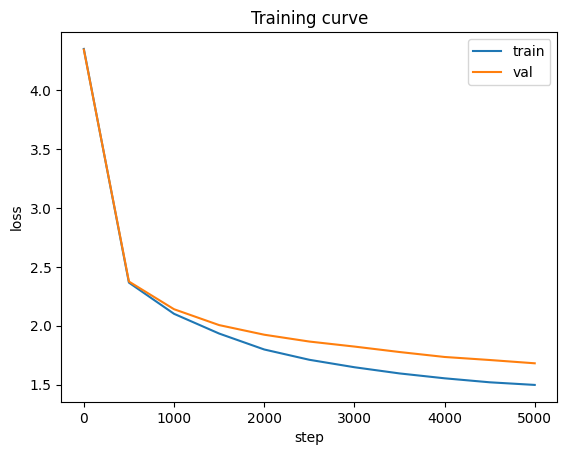

In [47]:
import matplotlib.pyplot as plt

plt.plot(history['step'], history['train'], label='train')
plt.plot(history['step'], history['val'], label='val')
plt.xlabel('step')
plt.ylabel('loss')
plt.legend()
plt.title('Training curve')
plt.savefig('loss_curve.png', dpi=150)
plt.show()

In [48]:
torch.save(m.state_dict(), 'gpt_shakespeare.pt')

context = torch.zeros((1, 1), dtype=torch.long, device=device)
sample = decode(m.generate(context, max_new_tokens=1000)[0].tolist())
with open('sample_output.txt', 'w') as f:
    f.write(sample)
print(sample[:300])


Be evoice, let nothing kill your castining joy
Grace incam fast the dead me to thee,
And recountly ever borns a writted old.
If me I weit adver for bsorne would swiming,
No curchmon other faster oftemnessy; or my lord:
Sold his no ne'er, nor more sucent to my somed,
But then untrighty as assispile,


In [49]:
m2 = GPTLanguageModel().to(device)
m2.load_state_dict(torch.load('gpt_shakespeare.pt', map_location=device))
m2.eval()
print(decode(m2.generate(context, max_new_tokens=300)[0].tolist()))


Shee done meethineful forthwalt
And may the king joys, six, if my bresin all,
Your someticause: all years willifuly villozed
And string your cornies; therefore--

Prhamer:
Only,---beling or gless!
Was long of descell to you with kin you donour.

KING RICHARD III:
Wapper your arsemniabely.

Second Th


In [50]:
from google.colab import files
files.download('gpt_shakespeare.pt')
files.download('loss_curve.png')
files.download('sample_output.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
# max_iters = 5000

# for iter in range(max_iters):

#     xb, yb = get_batch('train')

#     logits, loss = m(xb, yb)

#     optimizer.zero_grad(set_to_none=True)

#     loss.backward()

#     optimizer.step()

#     if iter % 500 == 0:

#         print(
#             f"step {iter}: loss {loss.item():.4f}"
#         )

In [46]:

context = torch.zeros(
    (1, 1),
    dtype=torch.long,
    device=device
)

generated = m.generate(
    context,
    max_new_tokens=1000
)

print(
    decode(generated[0].tolist())
)


Messure, it we softeigned wonce when her the very,
To not take almon backing his well'd mere thines see
Sirlitingin in the highness a word, and
The restrues his enI haste accomptrations, the all.
If thank withat my breforeing bromen the shall earth.
Since deset outwer Henry have lastle,
Have's coldry not judged from once unto afteribure
Ress night, stay just to men, 'tis queen, men's beer soule nighburned
Untongel villant I nother the deenant om Thries,
Ay, and lege find yet out so are holess ere
Sham such my soulding-drings, is some the deadk
Ald scall burning about when seek
Of mistrains even course.

ROMEO:
Trust where prince'd!
When so many numbrail,--as I was that beelo,
Ah, sinmoral o' ne, hath send way,
And then shall call'd before a banish'd,
No! with amonge, would talk witter thee tonguine,
I' though burnis honeins o'lifly, 'tis' fool.
Tido thee, of Sath,--as ne'er, try proud,
They are sent, Joa. Have ne'er do,
Jief Ripation.

DUKE VINCHE'er:
What me supper to heaven with
Mar